# Week 3: OLS Demand Model

In [18]:
import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None 
import pickle

import os
from importlib import reload

import matplotlib.pyplot as plt
import matplotlib 
# import seaborn as sns
%matplotlib inline
plt.style.use('ggplot')
from matplotlib.ticker import MultipleLocator

### load competition data and show some stats

In [19]:
df1 = pd.read_csv('duopoly_competition_details_good.csv')
df2=pd.read_csv('duopoly_competition_details_bad.csv')
df_comp_details = pd.concat([df1, df2], ignore_index=True)
df_comp_details.fillna(0, inplace=True)

df_comp_details['revenue'] = df_comp_details['price'] * df_comp_details['demand']

df_comp_details.head(3)

,competition_id,selling_season,selling_period,competitor_id,price_competitor,price,demand,competitor_has_capacity,calculation_duration,errors,revenue
0,3AHQ52,1,1,PinkDuck,70.1,65.0,0,True,0.0,0.0,0.0
1,3AHQ52,1,2,PinkDuck,71.5,65.0,0,True,0.0,0.0,0.0
2,3AHQ52,1,3,PinkDuck,72.9,65.0,0,True,0.0,0.0,0.0


In [20]:
df_comp_details['unique_selling_season_key'] = df_comp_details.apply(lambda r:
                                "%s_%s" % (r.competition_id,r.selling_season), axis=1)

In [21]:
dfx_rev = df_comp_details.groupby('unique_selling_season_key').agg({
    'revenue' : 'sum'
}).reset_index()
dfx_rev.head(3)

,unique_selling_season_key,revenue
0,339UBs_1,0.0
1,339UBs_10,30.0
2,339UBs_100,90.0


# Let us build our own demand model based on the competition data.

## => f(price, competitor_price) = demand

## idea:
- split selling_season into sub-intervals where we assume a constant demand model
    - e.g. selling period [1,20] assumed to have almost constant demand
- estimate the demand model per competition
- train on first 50 selling_seasons and evaluate on the last 50

3RCuyb


<Axes: >

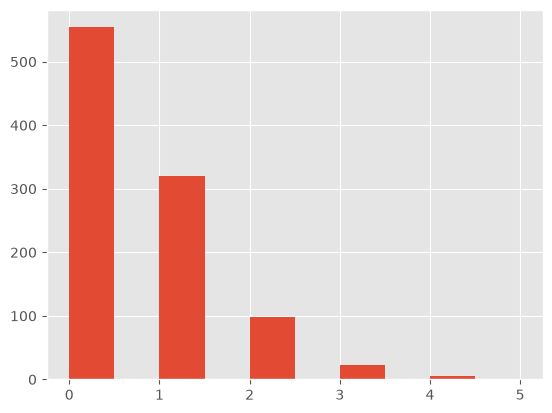

In [22]:
comp = df_comp_details.competition_id.unique()[1]
print(comp)

# filter on first competion_id
df = df_comp_details[df_comp_details.competition_id==comp ]

# concentrate on selling period in [1,20]
df = df[df.selling_period <= 20 ]

df_train = df[df.selling_season<=50]
df_test = df[df.selling_season>50]

df_train.demand.hist()

<Axes: >

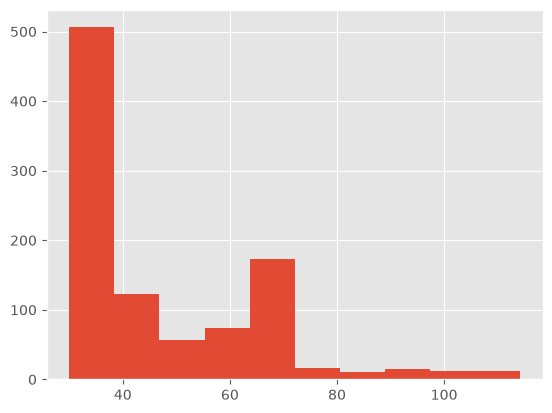

In [23]:
# df_train.head(35)
# df_train.demand.hist()
df_train.price.hist()

<Axes: >

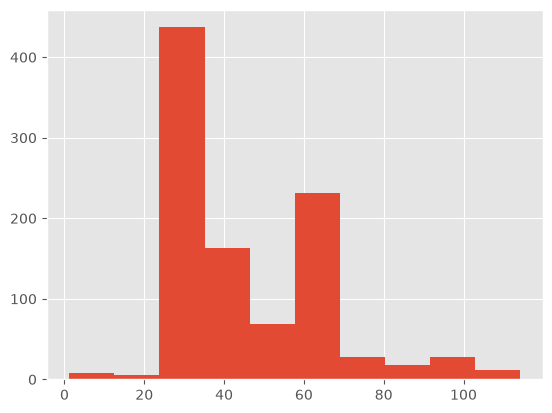

In [24]:
df_train.price_competitor.hist()

## (a) fit OLS model

In [25]:
import statsmodels.api as sm
# https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html

y = df_train.demand
X = df_train[['price', 'price_competitor']] 
X['intercept'] = 1


mod = sm.OLS(y, X)
# mod = sm.regression.quantile_regression.QuantReg(y,X)

res = mod.fit()

print(res.summary())

                            OLS Regression Results                            
Dep. Variable:                 demand   R-squared:                       0.057
Model:                            OLS   Adj. R-squared:                  0.055
Method:                 Least Squares   F-statistic:                     29.98
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           2.27e-13
Time:                        23:36:49   Log-Likelihood:                -1171.7
No. Observations:                1000   AIC:                             2349.
Df Residuals:                     997   BIC:                             2364.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
price               -0.0192      0.003  

## (b) predict demand based on function for
- own price = 30
- competitor price = 50

In [26]:
mod.predict(res.params, [30,50,1])

np.float64(0.9595708006109641)

## (c) simulate demand, our prices in [1,100] and competitor_price = 50

In [27]:

def est_demand(price, comp_price, para = res.params):
    demand = mod.predict(para, [price, comp_price, 1])
    demand = max(0,demand)
    return demand

df_sim = pd.DataFrame(columns = ['price','demand','rev'])
for p in np.arange(1,100,1):
    demand = est_demand(price=p, comp_price=90)
    rev = p * demand
    df_sim.loc[len(df_sim)] = [p,demand,rev]

    
df_sim.head()

,price,demand,rev
0,1.0,2.039492,2.039492
1,2.0,2.020253,4.040507
2,3.0,2.001015,6.003045
3,4.0,1.981777,7.927107
4,5.0,1.962539,9.812693


#### plot demand and revenue curve

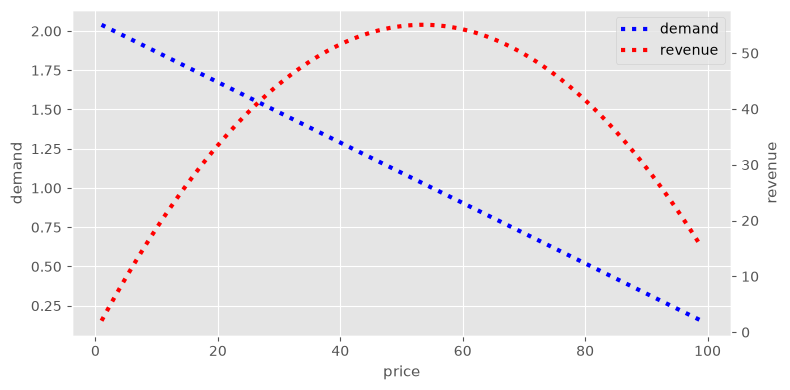

In [28]:
fig, ax = plt.subplots(figsize=(8,4))

ax.plot(df_sim['price'], df_sim['demand'], color='b', 
        linestyle='dotted', linewidth=3, label='demand')

ax_2 = ax.twinx()
ax_2.grid(False)
ax_2.plot(df_sim['price'], df_sim['rev'], color='r', 
        linestyle='dotted', linewidth=3, label='revenue')

ax_2.tick_params(axis="both", labelsize=10)
ax.tick_params(axis="both", labelsize=10)

# legend
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax_2.get_legend_handles_labels()
ax_2.legend(lines + lines2, labels + labels2, loc=0)

ax.set_xlabel('price', size=11)
ax.set_ylabel("demand" , size=11)
ax_2.set_ylabel("revenue" , size=11)

ax.grid(True)
fig.tight_layout()

plt.show()

## (d) compute estimated demand in computation details

In [29]:
df_eval = df_test[['unique_selling_season_key','selling_season','selling_period','price_competitor', 'price', 'demand']]

df_eval.head(5)

,unique_selling_season_key,selling_season,selling_period,price_competitor,price,demand
15000,3RCuyb_51,51,1,70.1,65.0,0
15001,3RCuyb_51,51,2,65.0,65.0,2
15002,3RCuyb_51,51,3,65.0,65.0,1
15003,3RCuyb_51,51,4,65.0,97.5,0
15004,3RCuyb_51,51,5,97.5,97.5,0


In [30]:
# estimate demand
# estimate demand
df_eval['est_demand'] = df_eval.apply(lambda r:
            est_demand(price=r.price, comp_price=r.price_competitor),
            axis=1)

# compute error metrics
df_eval['est_error'] = df_eval['est_demand'] - df_eval['demand']
df_eval['abs_est_error'] = df_eval['est_error'].abs()


df_eval.head(5)

,unique_selling_season_key,selling_season,selling_period,price_competitor,price,demand,est_demand,est_error,abs_est_error
15000,3RCuyb_51,51,1,70.1,65.0,0,0.548542,0.548542,0.548542
15001,3RCuyb_51,51,2,65.0,65.0,2,0.481985,-1.518015,1.518015
15002,3RCuyb_51,51,3,65.0,65.0,1,0.481985,-0.518015,0.518015
15003,3RCuyb_51,51,4,65.0,97.5,0,0.000000,0.000000,0.000000
15004,3RCuyb_51,51,5,97.5,97.5,0,0.280875,0.280875,0.280875


In [31]:
df_eval[['demand', 'est_demand', 'est_error', 'abs_est_error']].describe()

,demand,est_demand,est_error,abs_est_error
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,0.572000,0.604978,0.032978,0.623044
std,0.775511,0.182563,0.752412,0.422657
min,0.000000,0.000000,-3.301435,0.000000
25%,0.000000,0.515400,-0.345369,0.347226
50%,0.000000,0.666388,0.361510,0.538984
75%,1.000000,0.698565,0.672133,0.698565
max,4.000000,1.107229,1.107229,3.301435


### plot the actual demand vs. estimated demand for one test selling season

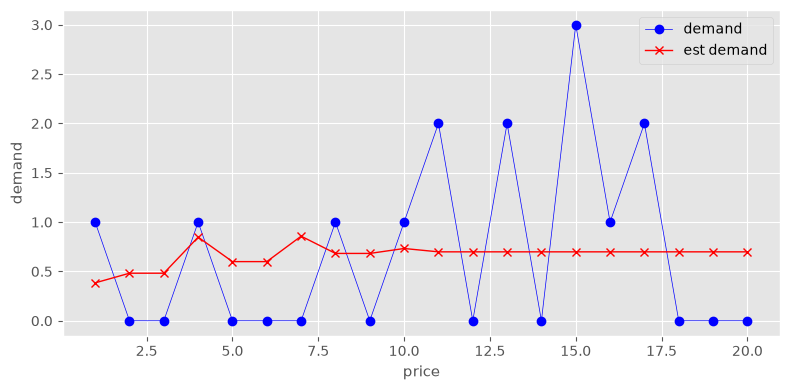

In [32]:
dfe = df_eval[df_eval.selling_season==60]

fig, ax = plt.subplots(figsize=(8,4))

ax.plot(dfe['selling_period'], dfe['demand'], color='b', 
        linestyle='-', marker='o', linewidth=0.5, markersize=6, label='demand')

ax.plot(dfe['selling_period'], dfe['est_demand'], color='r', 
        linestyle='-', marker='x', linewidth=1, markersize=6, label='est demand')

ax.legend( loc=0)

ax.set_xlabel('price', size=11)
ax.set_ylabel("demand" , size=11)

ax.grid(True)
fig.tight_layout()

plt.show()

# next tasks:
## (1) estimate five demand models covering the 100 period selling_season
## (2) estimate demand models for every simulation_id 
## (3) implement the demand model in your own simulation (last week simulation notebook)
## (4) implement the demand model estimation & next price optimization in your pricing algorithm

In [35]:
# Task 1 estimate five demand models covering the 100 period selling_season
import statsmodels.api as sm

df_good = pd.read_csv('duopoly_competition_details_good.csv')
df_bad = pd.read_csv('duopoly_competition_details_bad.csv') # Update filename if it differs slightly

# 2. Merge them together into one master DataFrame
df_comp_details = pd.concat([df_good, df_bad], ignore_index=True)
df_comp_details.fillna(0, inplace=True)

# 3. Calculate revenue
df_comp_details['revenue'] = df_comp_details['price'] * df_comp_details['demand']

# 4. Create your train and test splits (without any period filters, so all 100 periods are kept)
df_train = df_comp_details[df_comp_details.selling_season <= 50]
df_test = df_comp_details[df_comp_details.selling_season > 50]

print(f"Master training set loaded successfully with {len(df_train)} rows across all 100 periods!")

period_bins = [(1, 20), (21, 40), (41, 60), (61, 80), (81, 100)]
models_by_period = {}

for start, end in period_bins:
    # Filter training data for the specific period range
    df_interval = df_train[(df_train['selling_period'] >= start) & (df_train['selling_period'] <= end)]
    
    # Check if data exists for this interval to prevent crash
    if len(df_interval) == 0:
        print(f"Skipping periods {start}-{end}: No data found.")
        continue
        
    y = df_interval['demand']
    X = df_interval[['price', 'price_competitor']].copy()  # Using .copy() avoids pandas warnings
    X['intercept'] = 1
    
    # Fit the OLS model
    mod = sm.OLS(y, X)
    res = mod.finish() if hasattr(mod, 'finish') else mod.fit()
    
    models_by_period[(start, end)] = res
    print(f"Trained model for periods {start}-{end} (Observations: {len(df_interval)}, R-squared: {res.rsquared:.4f})")

Master training set loaded successfully with 50000 rows across all 100 periods!
Trained model for periods 1-20 (Observations: 10000, R-squared: 0.0507)
Trained model for periods 21-40 (Observations: 10000, R-squared: 0.0223)
Trained model for periods 41-60 (Observations: 10000, R-squared: 0.0239)
Trained model for periods 61-80 (Observations: 10000, R-squared: 0.0338)
Trained model for periods 81-100 (Observations: 10000, R-squared: 0.0470)


In [37]:
print(df_train.columns.tolist())

['competition_id', 'selling_season', 'selling_period', 'competitor_id', 'price_competitor', 'price', 'demand', 'competitor_has_capacity', 'calculation_duration', 'errors', 'revenue']


In [40]:
# Task 2 estimate demand models for every simulation_id 
import statsmodels.api as sm

models_by_comp = {}
for comp_id in df_train['competition_id'].unique():
    df_sub = df_train[df_train['competition_id'] == comp_id]
    if len(df_sub) > 10:
        y = df_sub['demand']
        X = df_sub[['price', 'price_competitor']].copy()
        X['intercept'] = 1
        
        mod = sm.OLS(y, X)
        res = mod.fit()
        if pd.isna(res.rsquared):
            print(f"Warning: Competition ID {comp_id} resulted in NaN R-squared. Skipping or using fallback model.")
            continue
        models_by_comp[comp_id] = res
        print(f"Competition ID {comp_id}: R-squared = {res.rsquared:.4f}")

Competition ID 3AHQ52: R-squared = 0.0845
Competition ID 3RCuyb: R-squared = 0.0953
Competition ID 3erHqy: R-squared = 0.1297
Competition ID 45cC4i: R-squared = 0.1456
Competition ID PnCp2V: R-squared = 0.0814
Competition ID VgXDDB: R-squared = 0.1211
Competition ID 339UBs: R-squared = 0.0049
Competition ID 3p8o46: R-squared = 0.0000
Competition ID 4EWNCR: R-squared = 0.1779


c:\Users\creep\Desktop\insa\bht\Learning_optimization\dpc_env\Lib\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - self.ssr / self.centered_tss
